# 06 · Informe final

**PISA 2025, inteligencia artificial y desigualdad educativa en Argentina**

Este informe resume lo que encontramos en los notebooks 00 a 05. Todas las cifras salen de las tablas guardadas en `reports/tables/`, que a su vez salen de los notebooks ejecutados. Está pensado para docentes y comunidad educativa.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

raiz = Path.cwd()
while not (raiz / "README.md").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("No se encontró README.md: ejecutá el notebook dentro del proyecto.")
    raiz = raiz.parent

carpeta_figuras = raiz / "reports" / "figures"
carpeta_tablas = raiz / "reports" / "tables"

resultados = pd.read_csv(carpeta_tablas / "03_resultados_hipotesis.csv")
sensibilidad = pd.read_csv(carpeta_tablas / "04_sensibilidad.csv")
exploratorias = pd.read_csv(carpeta_tablas / "05_hipotesis_exploratorias.csv")
exclusiones = pd.read_csv(carpeta_tablas / "02_exclusiones.csv")
print("Tablas leídas.")

Tablas leídas.


## 1. Resumen

**Palabras que usamos**
- **ESCS:** índice de nivel socioeconómico de PISA (se arma con el nivel educativo de los padres, los bienes y los libros del hogar). No es el ingreso.
- **Cuartil:** se ordena a los estudiantes de Argentina por ESCS y se los divide en cuatro grupos iguales. "Cuartil más alto" = el 25 % de mayor nivel socioeconómico; "cuartil más bajo" = el 25 % de menor nivel.
- **Frecuencia de uso de IA:** escala de 1 (nunca o casi nunca) a 5 (todos los días o casi). "Seguido" = una vez por semana o más.
- **Ajustar:** comparar estudiantes que son parecidos en otras características (en este caso ESCS, sexo y grado) para ver cuánto de una diferencia se debe a ellas.
- **Asociación:** dos cosas que van juntas. No significa que una cause la otra.

**Pregunta.** ¿Cómo se asocian el contexto socioeconómico y las formas de uso de IA con el rendimiento de los estudiantes argentinos en PISA 2025?

**Hipótesis principales (H1 a H3)**
1. **H1 · El contexto socioeconómico se asocia fuertemente con el rendimiento.** El cuartil de mayor nivel socioeconómico supera en unos 82 puntos de ciencias al de menor nivel.
2. **H2 · El uso frecuente de IA es más común en estudiantes de mayor nivel socioeconómico.** Entre 13 y 17 puntos porcentuales más de uso semanal o diario según la actividad.
3. **H3 · Sin ajustar, usar IA seguido se asocia con mayor puntaje en ciencias** al investigar un tema, ayudar a aprender y resumir un texto, pero no de forma concluyente al redactar borradores. **Ojo:** esta comparación no tiene en cuenta que los estudiantes de mayor nivel socioeconómico usan más IA y también rinden más; ver el primer complemento.

**Complementos (H4, H5 y HC1)**
4. **H4 · Al tener en cuenta el contexto (ESCS, sexo y grado), la asociación de H3 se reduce a menos de la mitad:** alrededor de 4 puntos por cada punto de frecuencia. Persiste al investigar un tema y al ayudar a aprender; al resumir un texto ya no es concluyente.
5. **H5 (exploratoria) · No hay evidencia suficiente de que la asociación cambie según el nivel socioeconómico.**
6. **HC1 · Hallazgo inesperado:** entre los estudiantes a quienes se les hicieron las preguntas de IA, alrededor del 29 % (3.091 de 10.566) no las contestó. Esos estudiantes tienen unos 66 puntos menos de ciencias (54 al ajustar por ESCS).

**Hipótesis exploratorias (planteadas después de ver los resultados anteriores)**
7. **HC3 · La IA se usa más entre quienes más rinden:** el cuartil de mayor rendimiento en ciencias usa IA semanal o diariamente 16,6 puntos porcentuales más que el de menor rendimiento.
8. **HC4 · La brecha de uso se da sobre todo entre escuelas:** dentro de una misma escuela la asociación entre nivel socioeconómico y uso de IA es menos de la mitad que en el total.
9. **HC2 · No se sostuvo** que el tipo de uso (investigar y aprender contra redactar) cambie con el nivel socioeconómico.

**Lo que no podemos decir.** Que la IA mejore o empeore el aprendizaje. Son asociaciones: es igualmente posible que quienes rinden más usen más la IA, o que otras características de los estudiantes expliquen ambas cosas. Además, los resultados sobre IA valen para quienes contestaron esas preguntas, que no son iguales al total de estudiantes. El uso de IA es lo que cada estudiante dice de sí mismo (autorreporte).

Una advertencia técnica: se hicieron muchas estimaciones (27 en el notebook 03 y 14 en el 04) y solo se corrigió por comparaciones múltiples en H3, así que los resultados con p entre 0,01 y 0,05 son indicios más débiles que los demás.

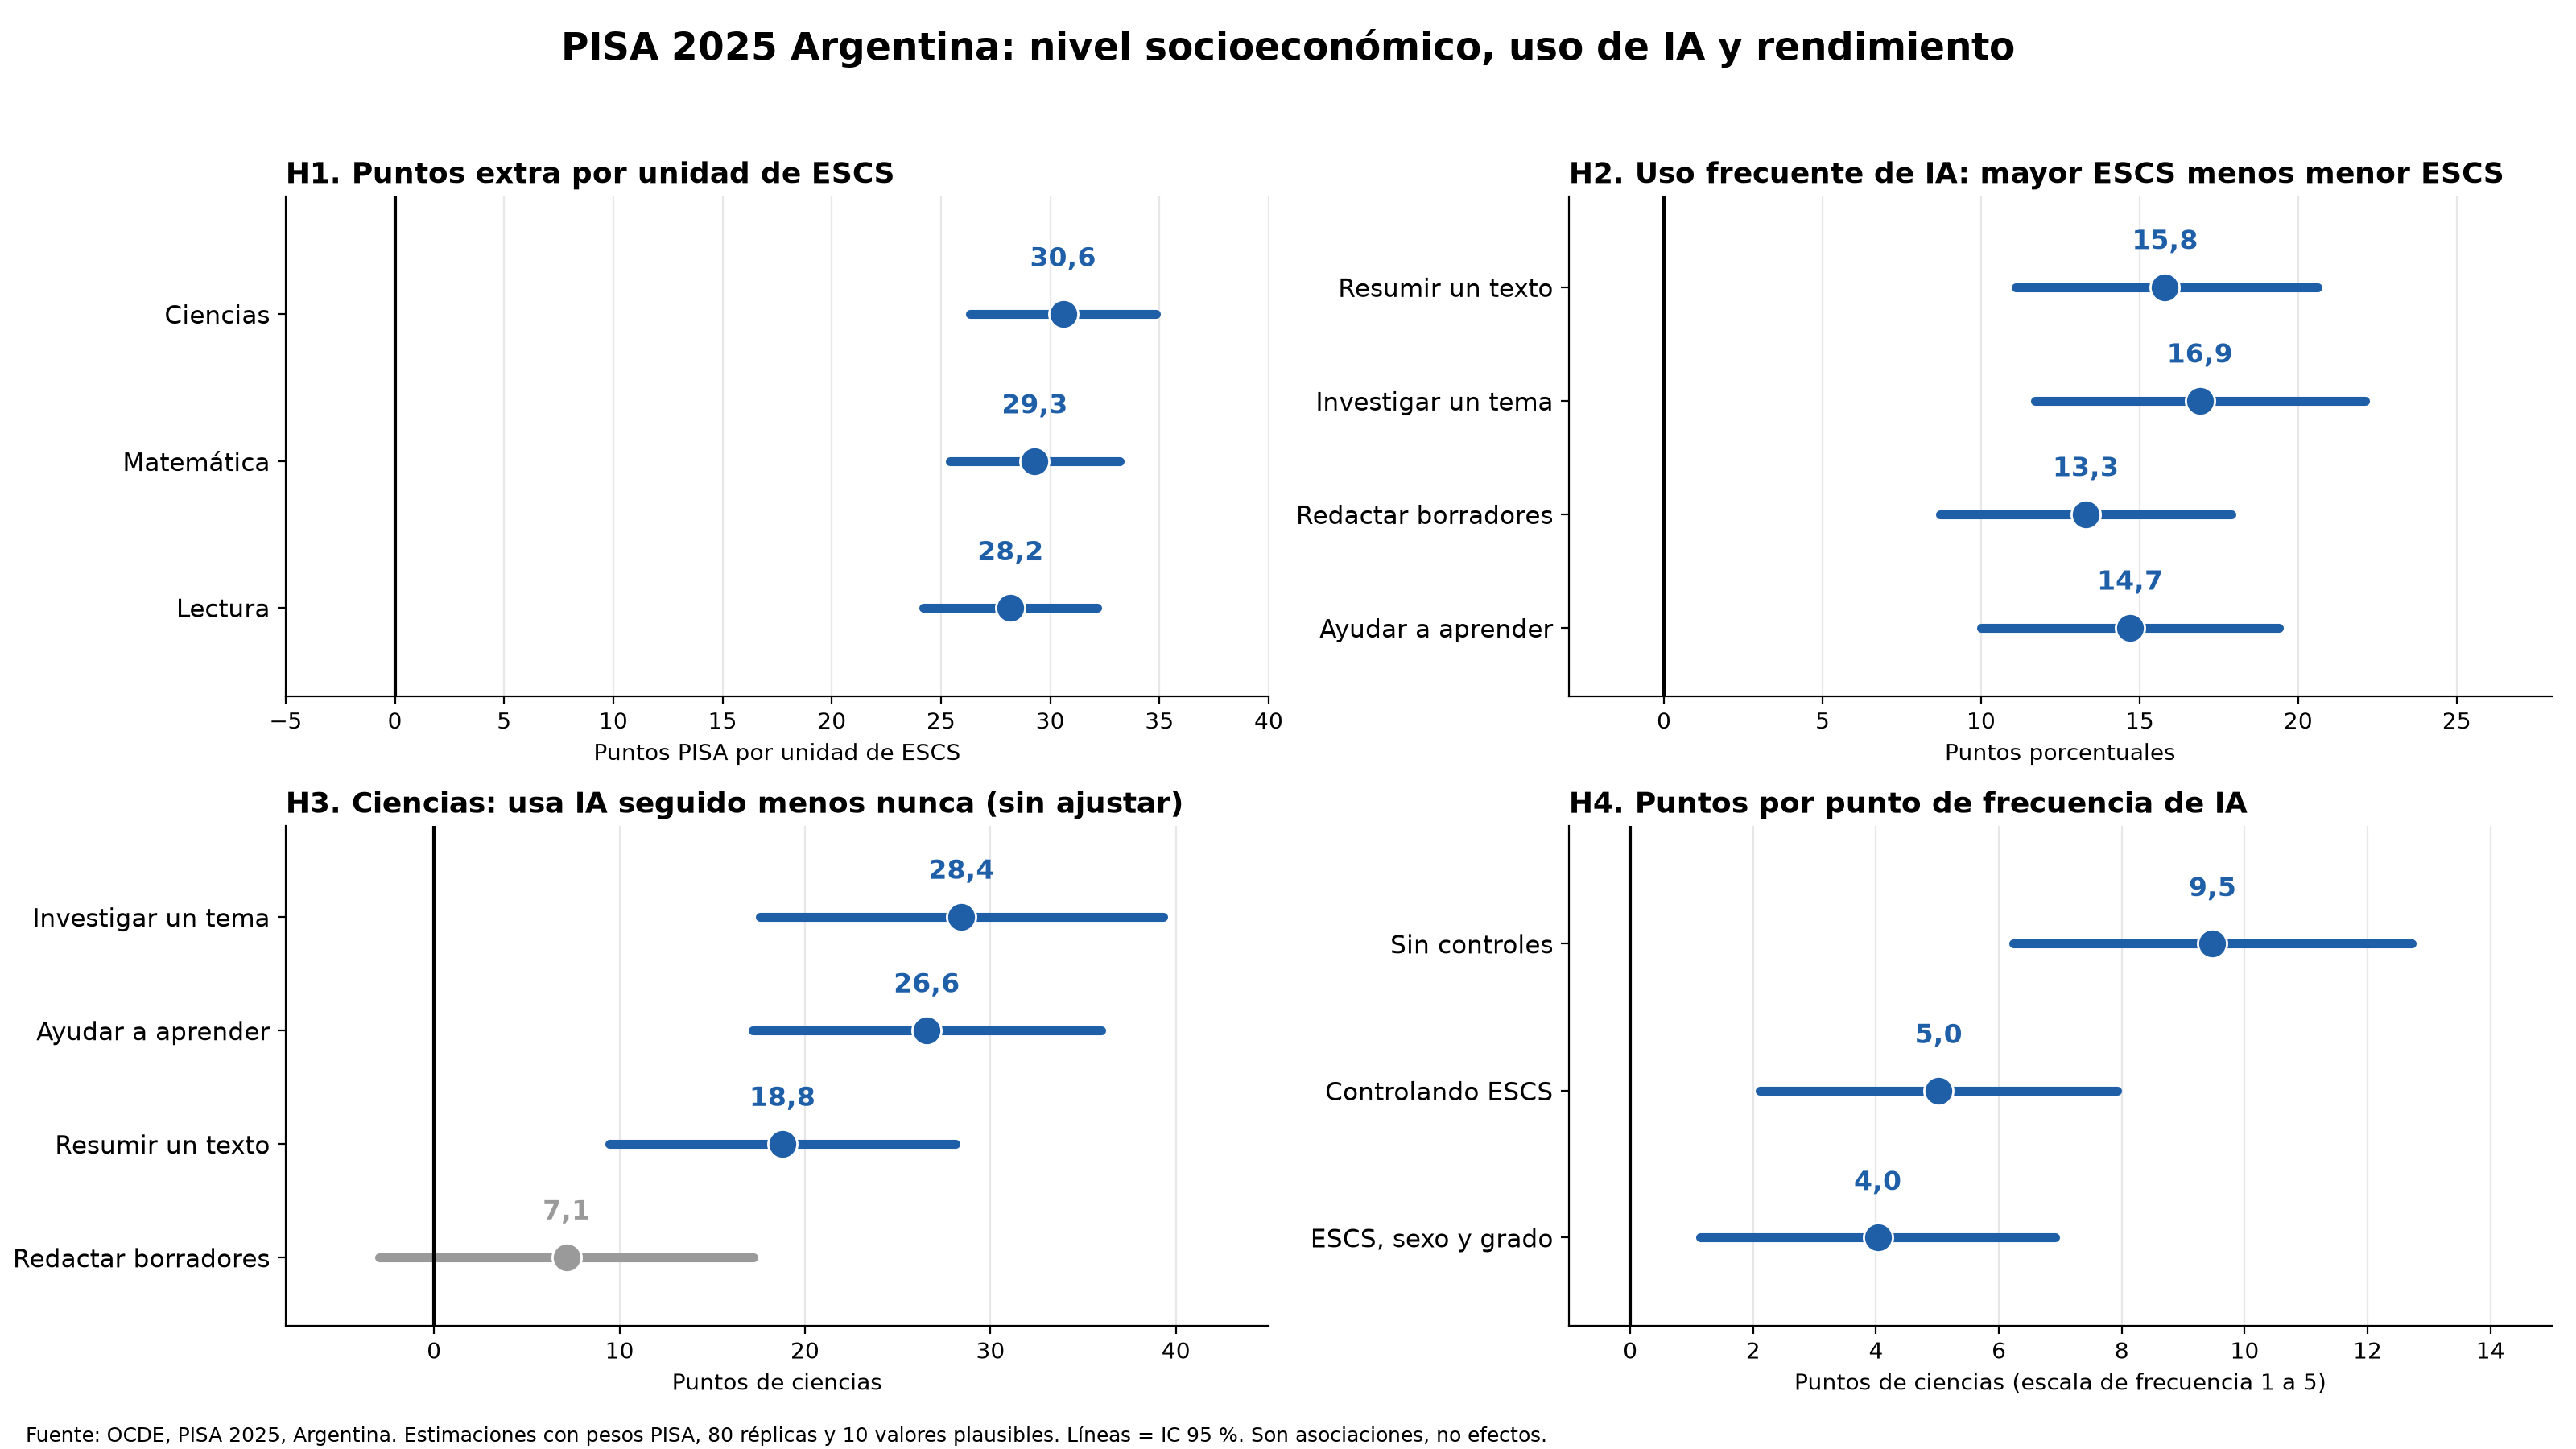

In [2]:
display(Image(filename=str(carpeta_figuras / "06_panel_resumen.png")))

## 2. Datos y método

- **Fuente:** OCDE, PISA 2025, archivo de estudiantes. Argentina: 11.092 estudiantes de 412 escuelas.
- **Rendimiento:** valores plausibles de ciencias (principal), matemática y lectura.
- **Nivel socioeconómico:** índice ESCS de PISA, dividido en cuartiles de Argentina.
- **Uso de IA:** PISA pregunta con qué frecuencia se usan chatbots de IA para cuatro actividades escolares (resumir un texto, investigar un tema, redactar borradores y ayudar a aprender). No distingue "copia directa" ni los demás perfiles que habíamos imaginado al principio.
- **Estadística:** todas las estimaciones usan el peso final de PISA, los 80 pesos replicados y los 10 valores plausibles, para que los errores y los intervalos reflejen cómo se armó la muestra.

Cuántos estudiantes se usan en cada análisis (nadie se elimina del archivo; cada análisis usa los que tienen las variables que necesita):

In [3]:
print(exclusiones.to_string(index=False))

                                          muestra  estudiantes  % del total
                         Estudiantes de Argentina        11092        100.0
                             Con ESCS válido (H1)         9808         88.4
       Con las 4 preguntas de IA (H3 sin ajustar)         7475         67.4
Con ESCS y las 4 preguntas de IA (H2, H3, H4, H5)         7191         64.8
            Anterior + sexo y grado (H4 ajustado)         7191         64.8


## 3. Respuesta a cada hipótesis

H1, H2 y H3 son las hipótesis principales. H4, H5 y HC1 se presentan como complementos; todas estaban planteadas desde el principio (salvo HC1, que surgió al preparar los datos) y se informan completas.

Cada hipótesis se resume con una de tres frases: *evidencia compatible con una asociación*, *evidencia insuficiente* o *no evaluable con estos datos*. "Evidencia insuficiente" no quiere decir que no haya asociación.

In [4]:
resumen = resultados[["hipotesis", "parametro", "n", "estimacion", "ic95_inferior", "ic95_superior", "p_texto", "veredicto"]]
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 90)
print(resumen.to_string(index=False))

hipotesis                                                                                                                      parametro     n  estimacion  ic95_inferior  ic95_superior p_texto                     veredicto
       H1                                                                      Pendiente de ESCS en Ciencias (puntos por unidad de ESCS)  9808      30.585         26.334         34.836 <0,0001 compatible con una asociación
       H1                                                                    Pendiente de ESCS en Matemática (puntos por unidad de ESCS)  9808      29.290         25.414         33.166 <0,0001 compatible con una asociación
       H1                                                                       Pendiente de ESCS en Lectura (puntos por unidad de ESCS)  9808      28.180         24.201         32.159 <0,0001 compatible con una asociación
       H1                                                                           Ciencias: cuartil 4 de E

### H1 · Nivel socioeconómico y rendimiento: se sostiene

Por cada unidad más de ESCS, el puntaje de ciencias es en promedio 30,6 puntos más alto (IC 95 %: 26,3 a 34,8). El cuartil más alto de ESCS supera al más bajo en 82,4 puntos (70,2 a 94,5). El patrón es parecido en matemática y lectura. **Evidencia compatible con una asociación**, de magnitud grande.

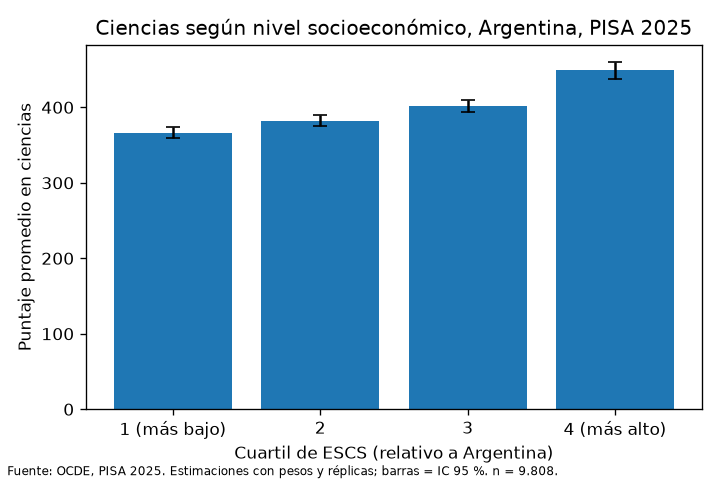

In [5]:
display(Image(filename=str(carpeta_figuras / "03_ciencias_por_cuartil_escs.png")))

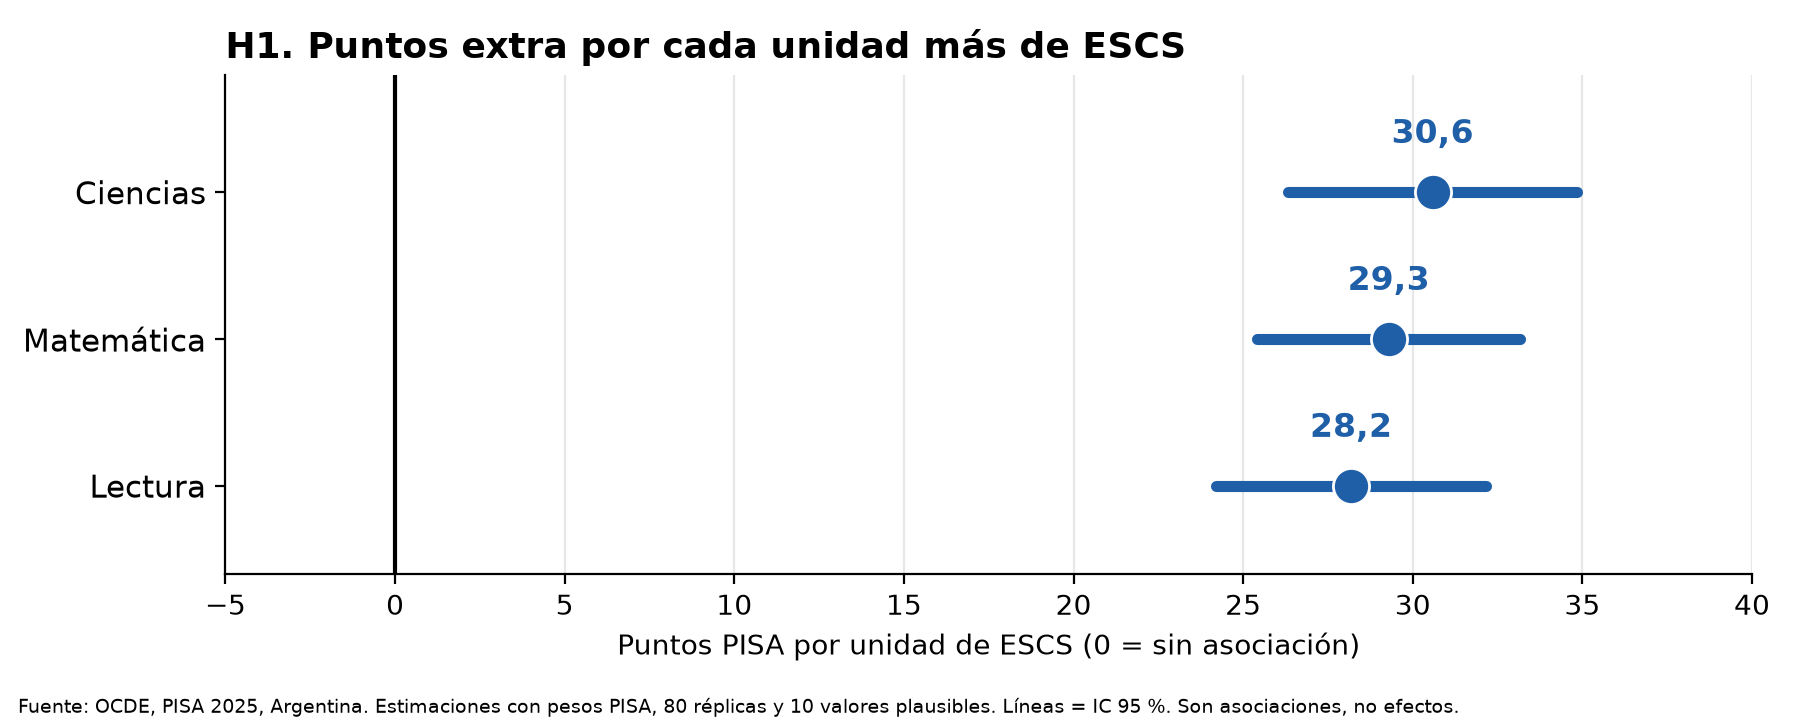

In [6]:
display(Image(filename=str(carpeta_figuras / "06_h1_escs_rendimiento.png")))

### H2 · Uso de IA y nivel socioeconómico: se sostiene

Entre quienes contestaron, el uso frecuente de IA es más común en el cuartil de mayor ESCS que en el de menor ESCS en las cuatro actividades (diferencias de 13 a 17 puntos porcentuales). **Evidencia compatible con una asociación**: hay una brecha de uso que acompaña la brecha socioeconómica.

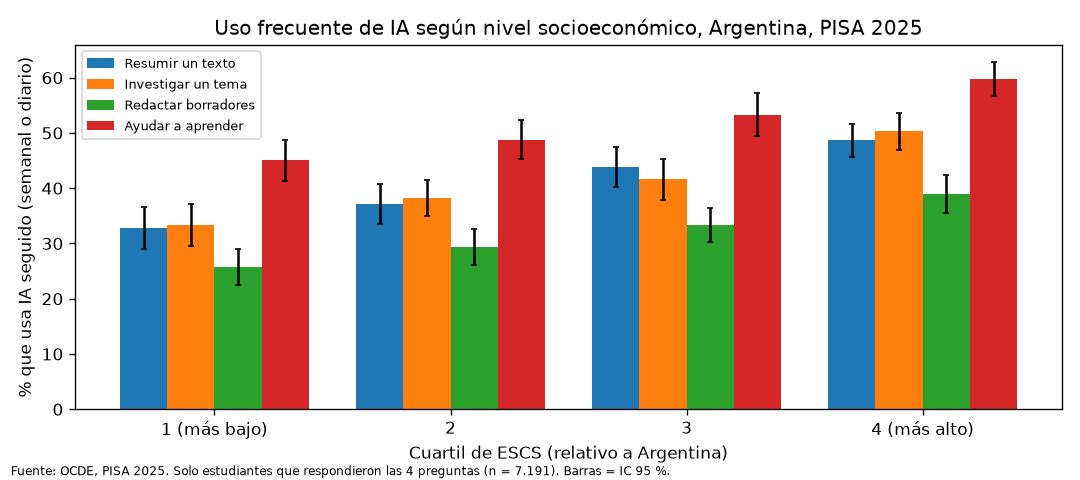

In [7]:
display(Image(filename=str(carpeta_figuras / "03_ia_seguido_por_cuartil_escs.png")))

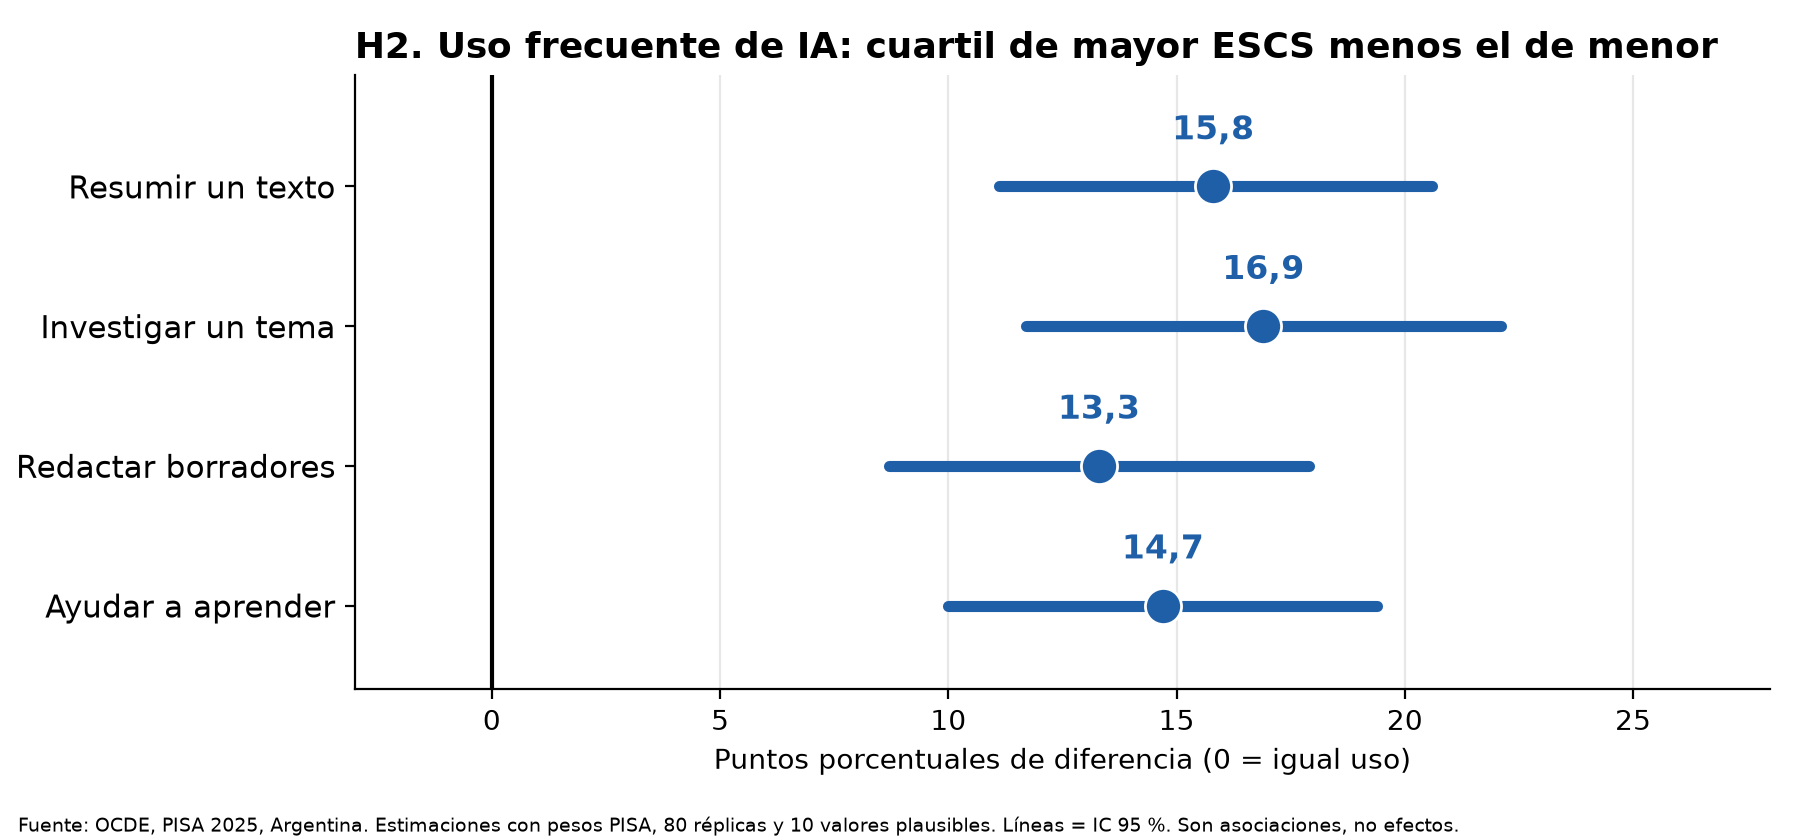

In [8]:
display(Image(filename=str(carpeta_figuras / "06_h2_uso_por_escs.png")))

### H3 · Rendimiento según el uso de IA, sin ajustar: se sostiene en tres de cuatro actividades

Quienes usan IA seguido (una vez por semana o más) tienen más puntaje de ciencias que quienes nunca la usan en investigar un tema (+28,4 puntos), ayudar a aprender (+26,6) y resumir un texto (+18,8). En redactar borradores el resultado no es concluyente (+7,1; el intervalo incluye el cero). Para usar IA solo *a veces* no hay evidencia suficiente de una diferencia con no usarla (en redactar borradores el resultado es -8,5; IC 95 %: -18,0 a 0,9, cerca del límite). **Evidencia compatible con una asociación** para uso frecuente en tres actividades; **evidencia insuficiente** en el resto.

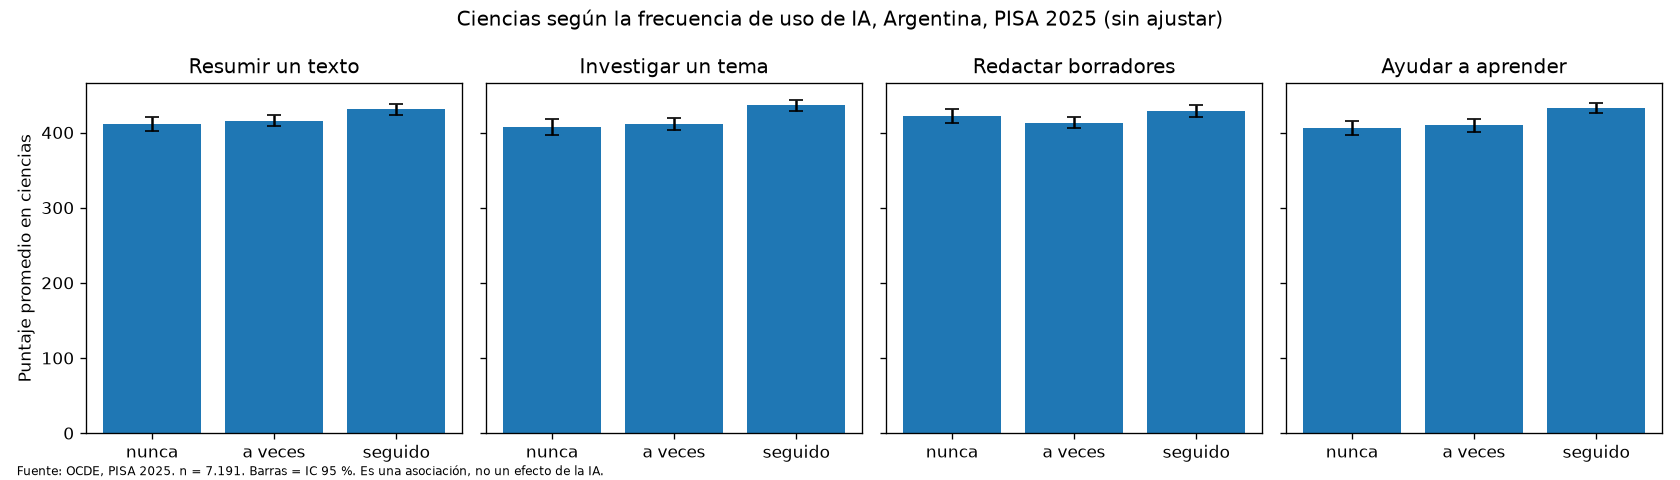

In [9]:
display(Image(filename=str(carpeta_figuras / "03_ciencias_por_frecuencia_ia.png")))

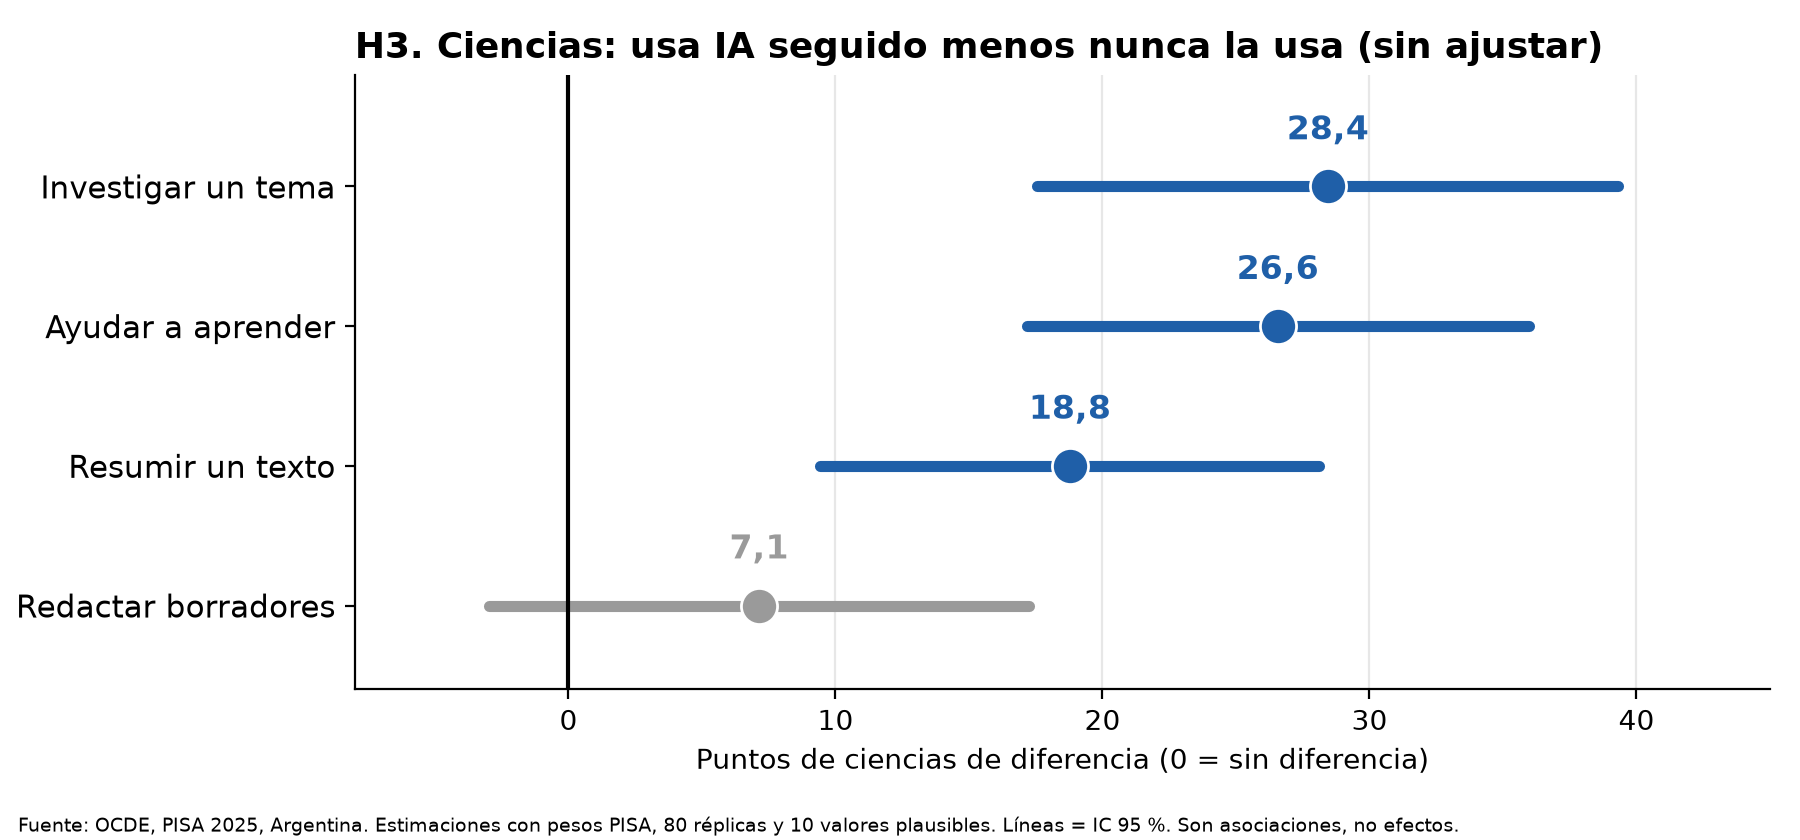

In [10]:
display(Image(filename=str(carpeta_figuras / "06_h3_rendimiento_por_uso.png")))

### Complemento · H4 · Uso de IA y rendimiento ajustando por el contexto: se sostiene, pero es modesta

Ajustando por ESCS, sexo y grado, la asociación baja de +9,5 a **+4,0 puntos por punto de frecuencia** (IC 95 %: 1,1 a 6,9). Es decir, más de la mitad de la diferencia inicial va junto con el nivel socioeconómico. Por actividad persiste en investigar un tema y ayudar a aprender (alrededor de +5), y no es concluyente en resumir y redactar borradores. **Evidencia compatible con una asociación condicional, de tamaño modesto.**

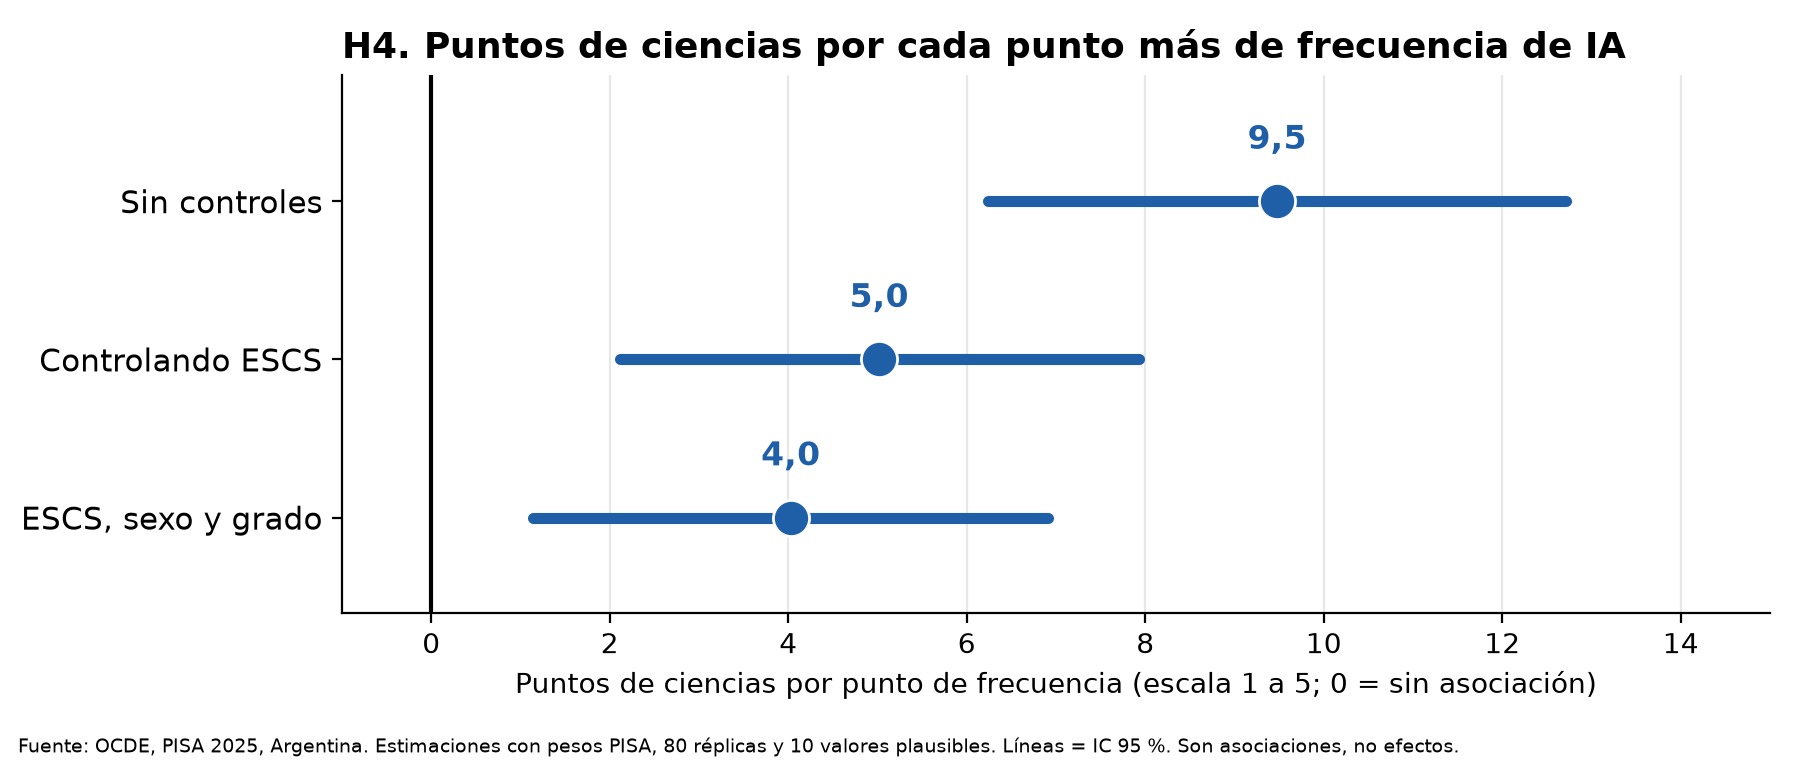

In [11]:
display(Image(filename=str(carpeta_figuras / "06_h4_al_controlar.png")))

### Complemento · H5 (exploratoria) · ¿Cambia la asociación según el nivel socioeconómico?: no concluyente

La interacción es de +2,4 puntos (IC 95 %: -0,3 a 5,2): el intervalo incluye el cero, así que no se puede afirmar que la asociación cambie según el ESCS. **Evidencia insuficiente.**

### Complemento · HC1 (complementaria) · Los que no contestaron las preguntas de IA

Surgió al preparar los datos y no estaba en el plan original. Los estudiantes que no contestaron las cuatro preguntas de IA (3.091 de 10.566 a quienes se les hicieron; se excluyen 526 a quienes la pregunta no se administró) tienen **66,0 puntos menos de ciencias** que los que sí contestaron (IC 95 %: 57,7 a 74,2), y 53,8 puntos menos si se ajusta por ESCS. **Evidencia compatible con una asociación.** Es la razón por la que los resultados sobre IA no deben extenderse sin cuidado a todos los estudiantes.

### Hipótesis exploratorias atrevidas (HC2, HC3 y HC4)

Se plantearon después de ver los resultados de H1 a H5, se registraron antes de calcularlas en `docs/bitacora.md` y se informan todas, con corrección de Bonferroni para tres (p < 0,0167). Detalle en el notebook 05.

- **HC2 · "Para qué" · no se sostiene.** Se esperaba que los estudiantes de mayor nivel socioeconómico usaran la IA más para investigar y aprender, y los de menor nivel más para redactar. La diferencia va en esa dirección pero es chica y no se distingue de cero (+0,08; IC 95 %: -0,03 a 0,19). La brecha de uso es más de *cuánto* que de *para qué*.
- **HC3 · "A quién llega" · se sostiene.** El cuartil de mayor rendimiento en ciencias usa IA semanal o diariamente **16,6 puntos porcentuales más** que el de menor rendimiento (IC 95 %: 11,3 a 22,0). No sabemos qué causa qué, y describe solo a quienes contestaron.
- **HC4 · "La misma escuela" · se sostiene, pero se achica.** La asociación entre nivel socioeconómico y frecuencia de uso de IA pasa de 0,185 a 0,080 al comparar estudiantes de una misma escuela (IC 95 %: 0,026 a 0,134): **más de la mitad de la brecha de uso se da entre escuelas**.

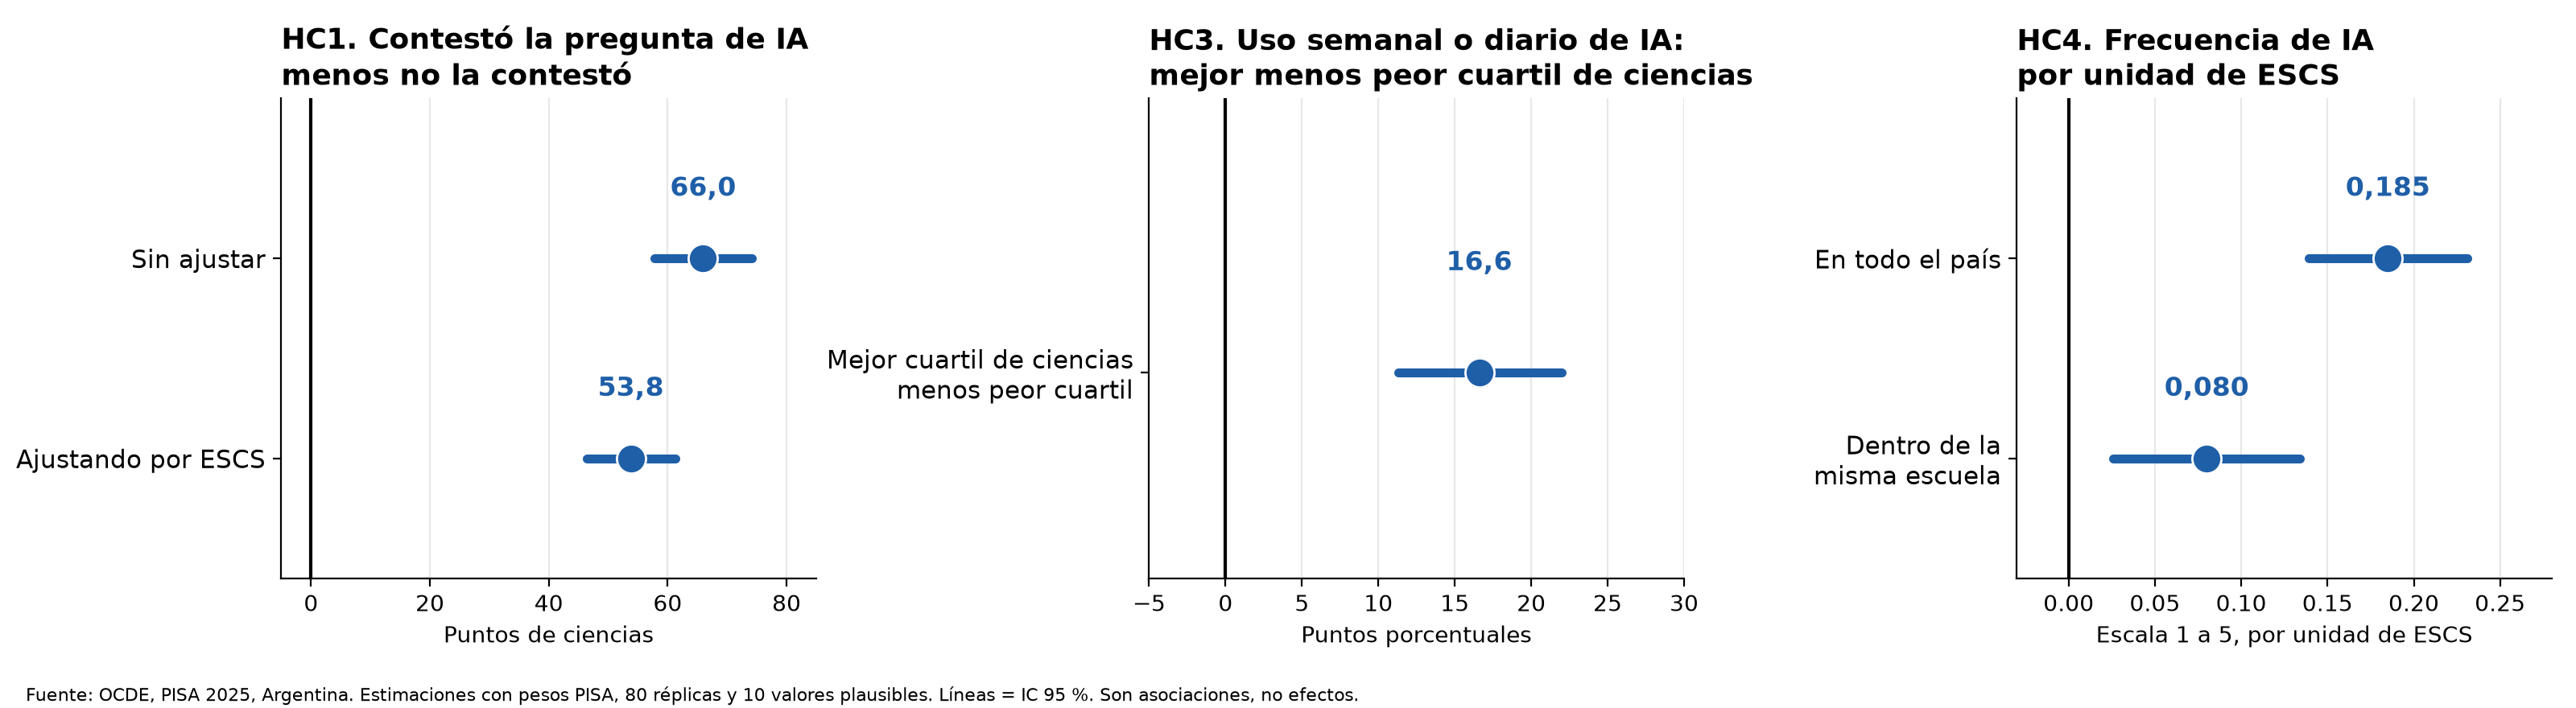

In [12]:
display(Image(filename=str(carpeta_figuras / "06_exploratorias.png")))

## 4. ¿Cambian las conclusiones si se miden las cosas de otra manera?

Se probaron pocas variantes decididas de antemano (otras áreas, otras medidas de IA, otros controles y un contraste más estricto). Detalle en el notebook 04.

In [13]:
print(sensibilidad[["hipotesis", "parametro", "n", "estimacion", "ic95_inferior", "ic95_superior", "p_texto"]].to_string(index=False))

            hipotesis                                                            parametro    n  estimacion  ic95_inferior  ic95_superior p_texto
              A. Área                                                      Ciencias (base) 7191       4.027          1.138          6.916  0.0063
              A. Área                                                           Matemática 7191       4.191          1.914          6.468  0.0003
              A. Área                                                              Lectura 7191       3.314          0.804          5.823  0.0097
      B. Medida de IA                       Índice AIUSESCH (puntos por unidad del índice) 7431       3.607          0.359          6.855  0.0295
      B. Medida de IA                 Usa IA alguna vez en alguna actividad (sí contra no) 7191       6.105         -6.504         18.714  0.3427
      B. Medida de IA           Usa IA semanal o diaria en alguna actividad (sí contra no) 7191      14.290          7.632  

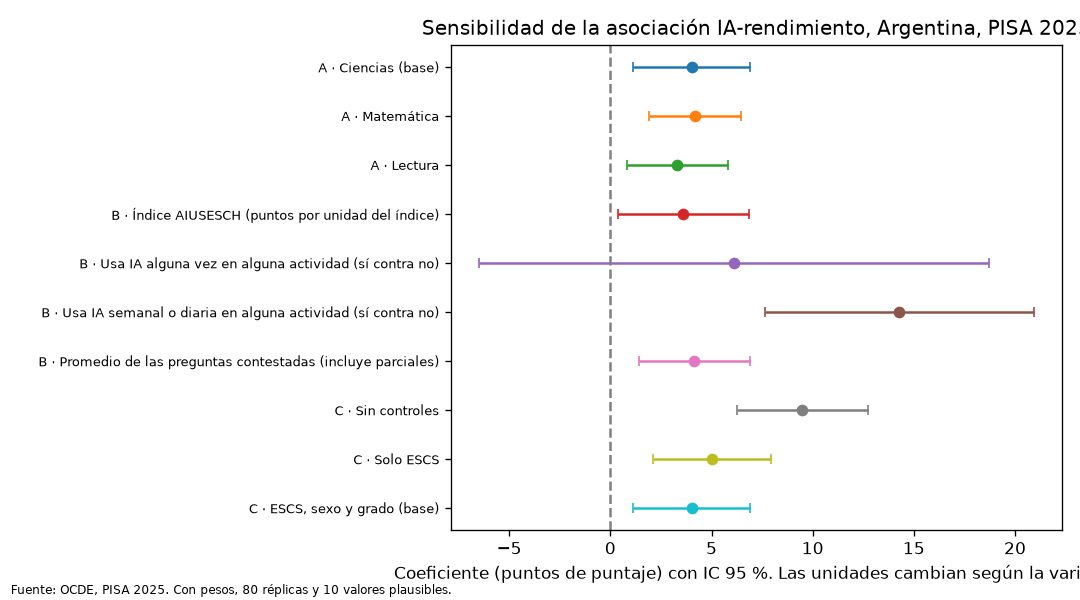

In [14]:
display(Image(filename=str(carpeta_figuras / "04_sensibilidad.png")))

**En resumen:** el signo positivo y el patrón por actividad se mantienen en todas las variantes. El tamaño de la asociación depende sobre todo de los controles que se usen. Con la definición "alguna vez" no hay resultado concluyente porque casi todos los estudiantes que contestaron (92 %) usaron IA alguna vez. Las variantes con otra escala (por ejemplo, "semanal o diario" sí o no, o el índice de PISA) no son comparables en tamaño con las demás; lo que se compara en ellas es el signo y la significación. Algunas variantes quedan cerca del límite (índice de PISA, p = 0,030; contraste de resumir todos los días, p = 0,021).

## 5. ¿Cuánta confianza se puede tener en cada hipótesis?

**Qué es y qué no es un p-valor.** Es la probabilidad de ver una diferencia al menos así de grande **si en realidad no hubiera ninguna asociación**. No es la probabilidad de que la hipótesis sea verdadera, ni dice si la diferencia es grande o importante. Un p-valor muy chico con una diferencia diminuta no sirve de mucho; por eso se miran juntos el p-valor, el tamaño y el intervalo de confianza.

**Cuándo se considera que una hipótesis "se sostiene".** Si el p-valor es menor que el umbral de su familia de pruebas: 0,05 para H1, H2, H4 y H5; 0,05 / 8 = 0,00625 para las ocho comparaciones de H3; y 0,05 / 3 = 0,0167 para HC2, HC3 y HC4. Se divide porque, cuando se hacen muchas pruebas, alguna sale "significativa" por azar (corrección de Bonferroni).

La tabla se arma con los valores guardados en `reports/tables/`.

In [15]:
filas_confianza = []
umbral_h3 = 0.05 / 8
umbral_hc = 0.05 / 3

# (tabla de origen, hipótesis, texto con el que empieza el parámetro, nombre corto, umbral)
pedidos = [
    (resultados, "H1", "Pendiente de ESCS en Ciencias", "H1 · ESCS y ciencias (por unidad de ESCS)", 0.05),
    (resultados, "H2", "Promedio de frecuencia de IA", "H2 · frecuencia de IA, Q4 menos Q1 de ESCS", 0.05),
    (resultados, "H3", "Investigar un tema: seguido menos nunca", "H3 · investigar, seguido menos nunca", umbral_h3),
    (resultados, "H3", "Ayudar a aprender: seguido menos nunca", "H3 · aprender, seguido menos nunca", umbral_h3),
    (resultados, "H3", "Resumir un texto: seguido menos nunca", "H3 · resumir, seguido menos nunca", umbral_h3),
    (resultados, "H3", "Redactar borradores: seguido menos nunca", "H3 · redactar, seguido menos nunca", umbral_h3),
    (resultados, "H4", "Coeficiente de la frecuencia de IA (promedio 1 a 5), ajustado", "H4 · IA y ciencias, ajustado", 0.05),
    (resultados, "H5", "Interacci", "H5 · interacción IA por ESCS", 0.05),
    (resultados, "HC1", "Ciencias: contest", "HC1 · contestó menos no contestó (sin ajustar)", 0.05),
    (exploratorias, "HC2", "Índice de tipo de uso", "HC2 · tipo de uso, Q4 menos Q1 de ESCS", umbral_hc),
    (exploratorias, "HC3", "Proporción que usa IA semanal", "HC3 · uso semanal, mejor menos peor cuartil", umbral_hc),
    (exploratorias, "HC4", "ESCS sobre frecuencia de IA, dentro de escuela", "HC4 · ESCS y uso dentro de la escuela", umbral_hc),
]

for pedido in pedidos:
    tabla = pedido[0]
    hipotesis = pedido[1]
    inicio = pedido[2]
    nombre = pedido[3]
    umbral = pedido[4]
    for indice in range(len(tabla)):
        fila = tabla.iloc[indice]
        if fila["hipotesis"] == hipotesis and fila["parametro"].startswith(inicio):
            if fila["p"] < umbral:
                veredicto = "supera el umbral"
            else:
                veredicto = "no alcanza"
            filas_confianza.append({
                "hipótesis": nombre,
                "estimación": round(fila["estimacion"], 3),
                "IC 95 %": str(round(fila["ic95_inferior"], 3)) + " a " + str(round(fila["ic95_superior"], 3)),
                "p": fila["p_texto"],
                "umbral": round(umbral, 5),
                "resultado": veredicto,
            })
            break

tabla_confianza = pd.DataFrame(filas_confianza)
print(tabla_confianza.to_string(index=False))

                                     hipótesis  estimación         IC 95 %       p  umbral        resultado
     H1 · ESCS y ciencias (por unidad de ESCS)      30.585 26.334 a 34.836 <0,0001 0.05000 supera el umbral
    H2 · frecuencia de IA, Q4 menos Q1 de ESCS       0.490   0.358 a 0.621 <0,0001 0.05000 supera el umbral
          H3 · investigar, seguido menos nunca      28.440 17.565 a 39.316 <0,0001 0.00625 supera el umbral
            H3 · aprender, seguido menos nunca      26.563 17.163 a 35.963 <0,0001 0.00625 supera el umbral
             H3 · resumir, seguido menos nunca      18.781  9.437 a 28.125 <0,0001 0.00625 supera el umbral
            H3 · redactar, seguido menos nunca       7.137 -2.968 a 17.242  0.1662 0.00625       no alcanza
                  H4 · IA y ciencias, ajustado       4.027   1.138 a 6.916  0.0063 0.05000 supera el umbral
                  H5 · interacción IA por ESCS       2.422   -0.306 a 5.15  0.0818 0.05000       no alcanza
HC1 · contestó menos no cont

### Lectura: nivel de confianza por hipótesis

La confianza no sale solo del p-valor. Se combina con el tamaño de la asociación, qué tan estable es en la sensibilidad (sección 4) y cuánto vale para toda la población.

| Hipótesis | Confianza | Por qué |
| --- | --- | --- |
| **H1** · ESCS y rendimiento | **Alta** | p menor que 0,0001, unos 30 puntos por unidad de ESCS en las tres áreas e intervalo lejos de 0. Es una asociación grande y muy estable. |
| **H2** · uso de IA según ESCS | **Alta para quienes contestaron** | p menor que 0,0001 en las cuatro actividades, de 13 a 17 puntos porcentuales. Pero vale solo para quienes contestaron las preguntas de IA (alrededor del 29 % no contestó). |
| **H3** · rendimiento según uso de IA (sin ajustar) | **Alta** en investigar y ayudar a aprender; **media** en resumir; **insuficiente** en redactar | Investigar (p = 0,0000003) y ayudar a aprender (p = 0,00000003) superan con mucho el umbral de Bonferroni (0,00625), y se mantienen con el contraste más estricto (todos los días contra nunca: +21,0 y +26,8). Resumir también supera el umbral (p = 0,00008), pero con el contraste estricto baja a p = 0,021. Redactar no se sostiene (p = 0,17). Sin ajustar, el tamaño está inflado por el contexto socioeconómico (ver H4): la confianza es en que la asociación existe, no en su tamaño. |
| **H4** · uso de IA y rendimiento, ajustado | **Media** | Con todos los controles p = 0,0063, por debajo de 0,05, pero con un intervalo ancho (1,1 a 6,9) y una asociación modesta (+4 puntos). Es sensible a cómo se mide la IA: el índice AIUSESCH da p = 0,030 y "alguna vez usó IA" no es concluyente. Por actividad solo investigar y ayudar a aprender se sostienen. |
| **H5** · cambia con el ESCS | **Insuficiente** | p = 0,08: el intervalo incluye al 0. No es evidencia de que no cambie, solo de que estos datos no alcanzan para decirlo. |
| **HC1** · quienes no contestaron | **Alta** | p menor que 0,0001 y unos 66 puntos de diferencia (54 ajustando por ESCS). Es la cifra más grande del estudio y condiciona cómo leer el resto. |
| **HC2** · tipo de uso por ESCS | **No se sostiene** | p = 0,15, mayor que 0,0167. No prueba que el uso sea igual, solo que no se detecta una diferencia. |
| **HC3** · a quién llega la IA | **Alta como asociación, exploratoria** | p menor que 0,0001, supera el umbral de Bonferroni (0,0167). No se sabe si la IA ayuda a rendir o si quienes rinden más la usan más. |
| **HC4** · la misma escuela | **Media, exploratoria** | p = 0,0036 dentro de la escuela, también bajo el umbral. La caída de 0,185 a 0,080 no se probó con una prueba formal de diferencia, solo se compararon los dos intervalos. |

**Qué puede hacer que estos p-valores sean algo optimistas o pesimistas**
- La varianza se calculó con una fórmula de réplicas (factor de Fay 0,5) que no se pudo confirmar en la documentación técnica provisional de PISA 2025. Si el factor fuera distinto, los errores estándar y los p-valores cambiarían, aunque las estimaciones no.
- Los resultados sobre IA valen para quienes contestaron esas preguntas, que no son un grupo al azar (HC1).
- Se hicieron varias pruebas más allá de las de la tabla (sensibilidad, por actividad). Los p-valores cercanos a 0,05 (por ejemplo 0,030 y 0,021 en la sensibilidad) hay que leerlos con cautela.
- Ningún p-valor, por chico que sea, convierte una asociación en una causa.

## 6. Lo que NO se puede afirmar

- **Que la IA cause un mejor o peor rendimiento.** PISA es una encuesta de un solo momento. Las asociaciones también pueden deberse a que quienes rinden más usan más la IA, o a características de los estudiantes que no medimos.
- **Que los resultados valgan para todos los estudiantes.** Alrededor del 29 % de los estudiantes a quienes se les hicieron las preguntas de IA no las contestó, y rinde bastante menos.
- **Nada sobre "copia directa" o perfiles de uso.** PISA no pregunta eso: solo la frecuencia de cuatro actividades.
- **Nada sobre los jóvenes que no están en la escuela.** PISA representa a estudiantes escolarizados de 15 años.
- **El uso de IA es autorreportado**, y el nivel socioeconómico es un índice relativo de Argentina, no el ingreso de las familias.
- **Hay supuestos técnicos sin confirmar:** el factor de Fay (0,5) de la fórmula de varianza no se verificó en la documentación técnica de PISA 2025 (que es provisional hasta 2027), y los resultados no se contrastaron con software estadístico de terceros, aunque una verificación separada, con otro código escrito para esa revisión, reprodujo cuatro de los resultados centrales. No se usó R ni otro paquete de terceros.
- **Comparaciones múltiples:** solo H3 se informó con corrección de Bonferroni; los resultados límite (por ejemplo p cercano a 0,05) deben leerse con cautela.

## 7. Conclusión

En Argentina, en PISA 2025, el nivel socioeconómico se asocia fuertemente con el rendimiento y también con la frecuencia de uso de IA: los estudiantes de mayor nivel socioeconómico usan más seguido estas herramientas. Entre quienes contestaron, el uso frecuente de IA en investigar, ayudar a aprender y resumir se asocia con mayor puntaje cuando no se tiene en cuenta el contexto. Al tenerlo en cuenta, la asociación se reduce a menos de la mitad, persiste al investigar y al ayudar a aprender, y deja de ser concluyente al resumir. No permite decir que la IA mejore el aprendizaje.

Para la comunidad educativa, lo más sólido que dejan los datos es la **brecha de uso**: no todos los estudiantes usan estas herramientas con la misma frecuencia, y esa diferencia acompaña la desigualdad socioeconómica que ya existe en el rendimiento. Para saber si usar IA ayuda a aprender haría falta un diseño que permita estudiar causas (por ejemplo, seguimiento en el tiempo o un estudio con intervención), que PISA no ofrece.

## 8. Posibles estudios siguientes (no probados)

Ideas que quedan abiertas:
- **Los que no contestaron:** estudiar con más detalle quiénes son y por qué no contestaron, que es el límite principal de este trabajo.
- **Entre escuelas:** si la brecha de uso entre escuelas se relaciona con características de las escuelas (por ejemplo, tipo de escuela o recursos digitales), para lo cual PISA tiene el cuestionario de escuelas.
- **Mirar el tiempo:** cuando existan nuevas ediciones de PISA, ver si la brecha de uso crece o se achica.

## 9. Qué revisar si se actualiza el trabajo

- Cuando se publique el informe técnico final de PISA 2025 (previsto para 2027): confirmar el factor de replicación y el tratamiento de los pesos.
- Si hay nuevos ciclos de PISA: revisar si cambiaron las preguntas de IA y la cobertura en Argentina.
- Ante cualquier cambio de la estructura de los archivos, los notebooks tienen controles de calidad que se detienen con un error.